# SECCION 1: Analisis inicial y limpieza de datos.

## Importacion de las librerias a utilizar

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.stats.proportion as prop
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Importacion del data set

In [6]:
dataset = pd.read_csv('./dataset/listings.csv.gz')
dataset.info(verbose=True, show_counts=True)
type(dataset)

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  str    
 9   host_id                                       29685 non-null  int64  
 1

pandas.DataFrame

## Primer obvservacion de columnas vacias

In [53]:
nulos = dataset[['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood','neighbourhood_group_cleansed', 'calendar_updated', 'instant_bookable']]
nulos.head(15)
#"host_since", "host_response_time", "host_response_rate", "host_acceptance_rate", "host_thumbnail_url", "host_neighbourhood", "host_total_listings_count", "host_verifications neighbourhood","neighbourhood_group_cleansed", "calendar_updated", "instant_bookable"

,neighborhood_overview,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_thumbnail_url,host_neighbourhood,host_total_listings_count,host_verifications,neighbourhood,neighbourhood_group_cleansed,calendar_updated,instant_bookable
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:

vacias = dataset.columns[dataset.isna().all()]
print(len(vacias), "columnas vacías:")
for col in vacias:
    print("-", col)

13 columnas vacías:
- neighborhood_overview
- host_since
- host_response_time
- host_response_rate
- host_acceptance_rate
- host_thumbnail_url
- host_neighbourhood
- host_total_listings_count
- host_verifications
- neighbourhood
- neighbourhood_group_cleansed
- calendar_updated
- instant_bookable


### Mostramos las 13 columnas vacias que encontramos.

### Limpiamos el dataset, dejando afuera las columnas vacias

In [55]:
dataset_limpio = dataset.drop(columns=vacias)
print("Luego del borrado: ")
print(dataset.shape, "->", dataset_limpio.shape)
print("\n")
dataset_limpio.info()

Luego del borrado: 
(29685, 90) -> (29685, 77)


<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   picture_url                                   29684 non-null  str    
 8   host_id                                       29685 non-null  int64  
 9   host_url               

In [56]:
dataset_limpio.describe() #describe no toma en cuenta los string, por eso las 48 cols

,id,scrape_id,host_id,host_profile_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_listings_count,latitude,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.968500e+04,2.968500e+04,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,...,25957.000000,25957.000000,25957.000000,25957.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,25957.000000
mean,9.329954e+17,2.026063e+13,1.081103e+16,1.476728e+18,7.506687,5.532727,5.323362,5.461142,19.602964,-34.592114,...,4.742028,4.869180,4.862890,4.874793,4.740904,15.194240,14.214654,0.701937,0.057773,1.481166
std,5.838355e+17,0.000000e+00,1.347071e+17,3.962312e+16,4.083517,3.376887,4.046868,3.296444,44.760560,0.017920,...,0.371037,0.291209,0.304637,0.244150,0.375315,32.782011,32.632849,3.608907,0.735822,1.640487
min,1.150800e+04,2.026063e+13,1.342600e+04,1.462507e+18,0.000000,0.000000,0.000000,0.000000,0.000000,-34.690056,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,6.233293e+17,2.026063e+13,3.506745e+07,1.462945e+18,4.000000,3.000000,2.000000,3.000000,1.000000,-34.603396,...,4.670000,4.850000,4.850000,4.850000,4.680000,1.000000,1.000000,0.000000,0.000000,0.370000
50%,1.046350e+18,2.026063e+13,1.585246e+08,1.467135e+18,8.000000,5.000000,4.000000,5.000000,3.000000,-34.591459,...,4.830000,4.950000,4.950000,4.940000,4.830000,3.000000,2.000000,0.000000,0.000000,0.980000
75%,1.431417e+18,2.026063e+13,4.644293e+08,1.470093e+18,11.000000,8.000000,8.000000,8.000000,16.000000,-34.581430,...,4.950000,5.000000,5.000000,5.000000,4.940000,12.000000,10.000000,0.000000,0.000000,2.050000
max,1.717830e+18,2.026063e+13,1.716955e+18,1.716967e+18,17.000000,11.000000,15.000000,11.000000,1375.000000,-34.534980,...,5.000000,5.000000,5.000000,5.000000,5.000000,208.000000,208.000000,52.000000,18.000000,41.660000


In [57]:
dataset_limpio.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,54019695,https://www.airbnb.com/rooms/54019695,20260629030533,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,https://a0.muscache.com/pictures/miso/Hosting-...,298874610,https://www.airbnb.com/users/show/298874610,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
1,41720307,https://www.airbnb.com/rooms/41720307,20260629030533,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,https://a0.muscache.com/pictures/37e687e2-2587...,220409424,https://www.airbnb.com/users/show/220409424,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
2,1090530711732696379,https://www.airbnb.com/rooms/1090530711732696379,20260629030533,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,https://a0.muscache.com/pictures/3adbe27a-af59...,488443857,https://www.airbnb.com/users/show/488443857,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
3,1482653002662185299,https://www.airbnb.com/rooms/1482653002662185299,20260629030533,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",https://a0.muscache.com/pictures/hosting/Hosti...,283840529,https://www.airbnb.com/users/show/283840529,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
4,1046394538968941382,https://www.airbnb.com/rooms/1046394538968941382,20260629030533,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,https://a0.muscache.com/pictures/hosting/Hosti...,550970409,https://www.airbnb.com/users/show/550970409,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


## Ahora siguen las variables que no nos dicen nada.


In [58]:
por_host = dataset_limpio.groupby("host_has_profile_pic")["host_id"].nunique()
porcentaje = (por_host / por_host.sum() * 100).round(1)

display(pd.DataFrame({"hosts": por_host, "%": porcentaje}))



,hosts,%
host_has_profile_pic,,
f,826,5.7
t,13730,94.3


### El 94,3 % de los hosts (13.730) tiene foto de perfil y solo el 5,7 % (826) no. Como casi no distingue entre publicaciones, la descartamos por ser una variable cuasi-constante.

In [59]:
scrape = dataset_limpio["scrape_id"].nunique()
print("Scapeos: ",scrape)

Scapeos:  1


### La variable scrape_id tiene un único valor: todos los datos son de un mismo relevamiento (realizado entre el 29/06 y el 02/07 de 2026). Por eso no aporta información y la descartamos.

In [60]:
dataset_limpio = dataset_limpio.set_index("id")
a_borrar = ["listing_url", "scrape_id", "picture_url", "host_url",
            "host_picture_url", "host_has_profile_pic", "host_thumbnail_url", "host_profile_url"]

ya_borradas = [c for c in a_borrar if c not in dataset_limpio.columns]
print("Ya no estaban:", ya_borradas)

dataset_limpio = dataset_limpio.drop(columns=[c for c in a_borrar if c in dataset_limpio.columns])
print(dataset_limpio.shape)
dataset_limpio

Ya no estaban: ['host_thumbnail_url']
(29685, 69)


,last_scraped,source,name,description,host_id,host_profile_id,host_name,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
id,,,,,,,,,,,,,,,,,,,,,
54019695,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,298874610,1469536348265366895,Pablo,6,9,6,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
41720307,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,220409424,1463206751662853765,Monica,7,8,7,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
1090530711732696379,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,488443857,1470198261120530992,Mathi,3,7,3,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
1482653002662185299,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",283840529,1469486631712739967,Liliana,6,10,3,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
1046394538968941382,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,550970409,1470463634022740655,Braian,2,6,2,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994022693284854325,2026-07-02,previous scrape,Lumiere Fair apparemment,Lumiere Fair has a modern and bright design th...,124702396,1468258412487155546,Nancy,9,2,4,...,4.86,4.43,4.71,4.86,NaN,3,3,0,0,0.21
1016061449243279308,2026-07-02,previous scrape,Charming Modern Studio in Caballito,Bright and stylish modern studio in the heart ...,344599,1462516210018566099,Welcome BA,15,5,15,...,4.90,4.85,4.90,4.84,NaN,31,31,0,0,2.85
1055203909942066000,2026-07-02,previous scrape,Lovely Moldes,"Kick back and relax in this calm, stylish space.",552774318,1470470371718015421,Jorge Enrique,2,6,2,...,4.91,4.94,4.97,4.94,NaN,1,1,0,0,1.14


In [61]:
print(dataset_limpio.isna().sum())

last_scraped                                       0
source                                             0
name                                               0
description                                      768
host_id                                            0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               3728
Length: 69, dtype: int64


In [62]:
dataset_limpio["description"].value_counts()

description
Keep it simple at this peaceful and centrally-located place.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 148
MOT is the leading agency for short term rentals in Buenos Aires and Mendoza. We also offer amazing monthly deals for long term stays. Contact us for further information!                                                                                                                                                                                                                                                                 

In [63]:
#print(dataset_limpio.describe())
print(dataset_limpio.info())

<class 'pandas.DataFrame'>
Index: 29685 entries, 54019695 to 994057877545566961
Data columns (total 69 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   last_scraped                                  29685 non-null  str    
 1   source                                        29685 non-null  str    
 2   name                                          29685 non-null  str    
 3   description                                   28917 non-null  str    
 4   host_id                                       29685 non-null  int64  
 5   host_profile_id                               29685 non-null  int64  
 6   host_name                                     29685 non-null  str    
 7   hosts_time_as_user_years                      29685 non-null  int64  
 8   hosts_time_as_user_months                     29685 non-null  int64  
 9   hosts_time_as_host_years                      29685 non-n

In [64]:
dataset_limpio.describe().T.map(lambda x: f"{x:,.2f}")

,count,mean,std,min,25%,50%,75%,max
host_id,"29,685.00","10,811,028,382,313,194.00","134,707,086,703,302,528.00","13,426.00","35,067,450.00","158,524,646.00","464,429,284.00","1,716,954,665,517,483,264.00"
host_profile_id,"29,685.00","1,476,728,304,345,758,720.00","39,623,121,484,344,208.00","1,462,506,732,948,986,624.00","1,462,945,332,714,168,320.00","1,467,134,572,700,400,384.00","1,470,093,125,315,035,648.00","1,716,967,263,657,568,000.00"
hosts_time_as_user_years,"29,685.00",7.51,4.08,0.00,4.00,8.00,11.00,17.00
hosts_time_as_user_months,"29,685.00",5.53,3.38,0.00,3.00,5.00,8.00,11.00
hosts_time_as_host_years,"29,685.00",5.32,4.05,0.00,2.00,4.00,8.00,15.00
hosts_time_as_host_months,"29,685.00",5.46,3.30,0.00,3.00,5.00,8.00,11.00
host_listings_count,"29,685.00",19.60,44.76,0.00,1.00,3.00,16.00,"1,375.00"
latitude,"29,685.00",-34.59,0.02,-34.69,-34.60,-34.59,-34.58,-34.53
longitude,"29,685.00",-58.42,0.03,-58.53,-58.44,-58.42,-58.39,-58.36
accommodates,"29,685.00",2.94,1.58,1.00,2.00,2.00,4.00,16.00


### Con este describe() podemos observar algunas cuestiones sobre presencia de outliers o errores en las siguientes variables:
-host_listings_count: Vemos que el maximo de cantidad, supera ampliamente al quartil Q3. mientras que con la variable calculada 'calculated_host_listings_count' esta situacion se normaliza.

-Los maximos valores de precio total y precio por noche son muy disparatados. (Alquileres de mas de 100 millones de pesos argentinos para una sola noche)

-Notamos en 'minimum_minimum_nights' el maximo toma 730 noches, donde estamos hablando de un valor outlier, ya que describe la naturaleza de un alquiler casi permanente (Mas de 2 años).

### Veamos algunas cuestiones relevantes

In [65]:
#¿Como se reparten los tipos de alojamiento?
tipo_alojamiento = pd.DataFrame([dataset_limpio["room_type"].value_counts(), round(dataset_limpio["room_type"].value_counts()/len(dataset_limpio)*100, 2)])
tipo_alojamiento

room_type,Entire home/apt,Private room,Hotel room,Shared room
count,26790.00,2616.00,141.00,138.00
count,90.25,8.81,0.47,0.46


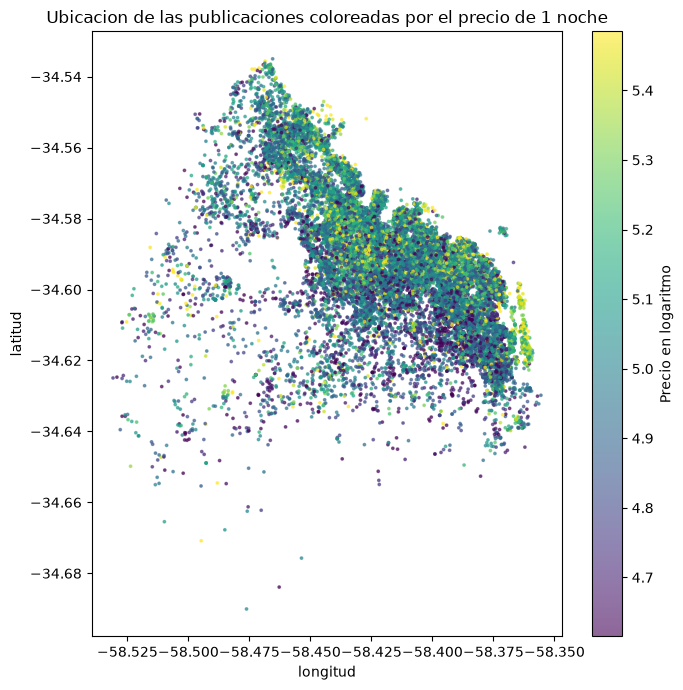

In [66]:
#¿Como se distribuyen los alquileres por zona y precio?

#Pasamos los precios por noche a notacion logaritmica
dataset_limpio["log_precio"] = np.log10(dataset_limpio["price_quote_price_per_night"])

#Sacamos los nulos
df_sin_nulos = dataset_limpio.dropna(subset=["log_precio"])

fig, ax = plt.subplots(figsize=(7,7))
sc = ax.scatter(df_sin_nulos["longitude"], df_sin_nulos["latitude"], c=df_sin_nulos["log_precio"], 
                s=3, cmap="viridis", alpha=.6, vmin=df_sin_nulos["log_precio"].quantile(0.05), vmax=df_sin_nulos["log_precio"].quantile(0.95))
plt.colorbar(sc, label="Precio en logaritmo")
ax.set_title("Ubicacion de las publicaciones coloreadas por el precio de 1 noche")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
plt.tight_layout()
plt.show()

In [67]:
dataset_limpio["neighbourhood_cleansed"].value_counts().head(4).cumsum()

neighbourhood_cleansed
Palermo         9703
Recoleta       13793
San Nicolas    16115
Retiro         17600
Name: count, dtype: int64

### Notamos que los precios, a medida que te alejas de la zona centrica, van disminuyendo, ademas de entender que la mayoria de alquileres estan agrupados en la zona mas turistica de Buenos Aires, ubicada mas cerca de barrios como recoleta, palermo, retiro y puerto madero. Generalmente estos son los puntos de mas turismo dentro de CABA.


### Con esto concluimos la etapa de limpieza, depuracion y exploracion.

# SECCION 2: Hipotesis propias y sus validaciones.

## Hipotesis univariada 
**Hipotesis:** La mayoría de la oferta de Airbnb en Buenos Aires está orientada al turismo de corta estancia, concentrando más del 70% de sus publicaciones en un requisito de estancia mínima (minimum_nights) de 1 a 3 noches.

**Justificación:** Buenos Aires es un destino urbano con alta rotación turística e itinerante. Entender el límite de noches mínimas permite determinar si el mercado opera predominantemente bajo la modalidad de alquiler vacacional/turístico a corto plazo o si está condicionado por esquemas de media/larga estancia (p. ej., contratos de 30 días para evitar regulaciones locales o apuntar a nómadas digitales).

### Limpieza de posibles nulos en la variable

In [68]:
df_h1 = dataset_limpio[['minimum_nights']].dropna().copy()

total_listings = len(df_h1)
estancia_corta = df_h1[df_h1['minimum_nights'] <= 3]
cant_estancia_corta = len(estancia_corta)
pct_estancia_corta = (cant_estancia_corta / total_listings) * 100

### Estadísticos descriptivos

In [69]:
media_noches = df_h1['minimum_nights'].mean()
mediana_noches = df_h1['minimum_nights'].median()
p25 = df_h1['minimum_nights'].quantile(0.25)
p75 = df_h1['minimum_nights'].quantile(0.75)

print(f"=== RESULTADOS H1 (UNIVARIADA) ===")
print(f"Total publicaciones analizadas: {total_listings}")
print(f"Publicaciones con minimum_nights <= 3: {cant_estancia_corta} ({pct_estancia_corta:.2f}%)")
print(f"Media: {media_noches:.2f} noches | Mediana: {mediana_noches:.1f} noches | IQR: [{p25:.0f} - {p75:.0f}]")

=== RESULTADOS H1 (UNIVARIADA) ===
Total publicaciones analizadas: 29682
Publicaciones con minimum_nights <= 3: 23136 (77.95%)
Media: 4.95 noches | Mediana: 2.0 noches | IQR: [1 - 3]


### Visualizacion de los datos

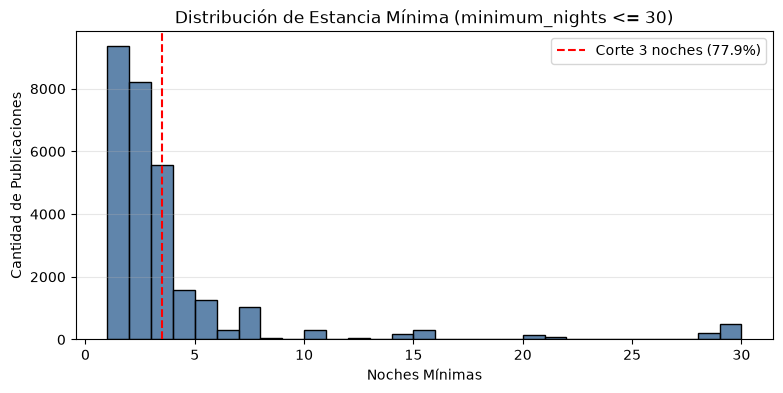

In [70]:
plt.figure(figsize=(9, 4))

sns.histplot(df_h1['minimum_nights'], bins=range(1, 31), kde=False, color='#2b5c8f')
plt.axvline(3.5, color='red', linestyle='--', label=f'Corte 3 noches ({pct_estancia_corta:.1f}%)')
plt.title('Distribución de Estancia Mínima (minimum_nights <= 30)') #Usamos un corte de 30 noches para visualizar mejor la distribución
plt.xlabel('Noches Mínimas')
plt.ylabel('Cantidad de Publicaciones')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

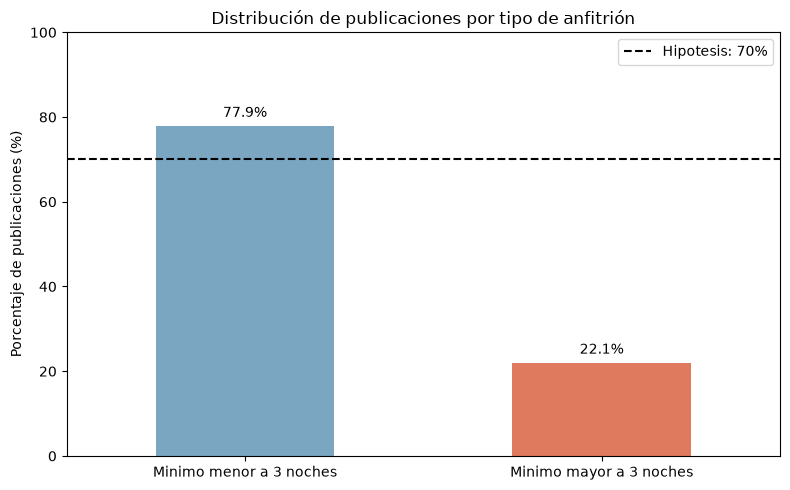

In [71]:
minimum_menor_3 = df_h1[df_h1['minimum_nights'] <= 3]
minum_mayores_3 = df_h1[df_h1['minimum_nights'] > 3]

# Porcentaje de publicaciones según si el anfitrión ofrece más de un alojamiento
publicaciones = pd.Series({
    "Minimo menor a 3 noches": minimum_menor_3.shape[0],
    "Minimo mayor a 3 noches": minum_mayores_3.shape[0],
})
porcentaje_publicaciones = publicaciones / publicaciones.sum() * 100

#Porcentaje_publicaciones consta con el porcentaje real de publicaciones por sobre la cantidad de publicaciones listadas.

ax = porcentaje_publicaciones.plot(kind="bar", figsize=(8, 5), color=["#7aa6c2", "#e07a5f"])
ax.axhline(70, color="black", linestyle="--", linewidth=1.5, label="Hipotesis: 70%")
ax.set_title("Distribución de publicaciones por tipo de anfitrión")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje de publicaciones (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for barra, valor in zip(ax.patches, porcentaje_publicaciones):
    ax.annotate(f"{valor:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")

plt.tight_layout()
plt.show()

### Vamos a utilizar un test t para proporciones, debido a que tenemos una comparacion de porcentajes.

In [72]:
#Hipotesis nula H0: El porcentaje de publicaciones con mínimo mayor a 3 noches es igual o menor al 70%.
#Hipotesis alternativa H1: El porcentaje de publicaciones con mínimo mayor a 3 noches es mayor al 70%.

alpha = 0.05  # Nivel de significancia

condicion = df_h1['minimum_nights'] <= 3
k_exitos = df_h1[condicion].shape[0]
n_total = df_h1.shape[0]
p_obvservada = k_exitos / n_total

print(f"Proporcion muestral observada: {p_obvservada:.4f} ({p_obvservada*100:.2f}%)")

#Test t de proporciones (Z)
stat, p_value = prop.proportions_ztest(count=k_exitos, nobs=n_total, value=0.7, alternative='larger')
print(f"Estadístico de prueba: {stat:.4f}")
print(f"Valor p: {p_value:.4f}")

if p_value < alpha:
    print("Rechazamos la hipótesis nula H0. Hay evidencia suficiente para aceptar la hipótesis alternativa H1.")
    print(f"El porcentaje de publicaciones con mínimo menor a 3 noches es significativamente mayor al 70%.")
else:
    print("No se puede rechazar la hipótesis nula H0. No hay evidencia suficiente para aceptar la hipótesis alternativa H1.")
    print(f"El porcentaje de publicaciones con mínimo menor a 3 noches no es significativamente mayor al 70%.")

Proporcion muestral observada: 0.7795 (77.95%)
Estadístico de prueba: 33.0194
Valor p: 0.0000
Rechazamos la hipótesis nula H0. Hay evidencia suficiente para aceptar la hipótesis alternativa H1.
El porcentaje de publicaciones con mínimo menor a 3 noches es significativamente mayor al 70%.


### Conclusion final: notamos que el p-valor del test esta por debajo de nuestro nivel de significancia, y ademas conocemos que el porcentaje de minimo de noches menores o igual a 3, es significativamente mayor, ya que es de el 77,9%.
### Entendemos que airbnb, por lo menos en buenos aires, esta dedicada en su mayoria a estadias cortas, para momentos turisticos de pocos dias.

In [73]:
dataset_limpio[['review_scores_rating', 'reviews_per_month']].head()

,review_scores_rating,reviews_per_month
id,,
54019695,NaN,NaN
41720307,4.56,0.16
1090530711732696379,4.67,0.34
1482653002662185299,4.84,1.78
1046394538968941382,NaN,NaN


## Hipotesis bivariada
**Hipotesis:** Los alojamientos gestionados por superhosts obtienen, en promedio, reseñas con calificacion significativamente mas altas de quienes no lo son

**Justificacion:** Los usuarios superhost son aquellos que son reonocidos por mejor desempeño dentro de la aplicacion, entonces, nos parece logico que aquellos que son superhosts, cuentan con propiedades listadas con reseñas positivamente mas altas que las de aquellos que no son superhost.

### Limpieza de datos

In [74]:
#Primero limpiamos los datos eliminando las filas con valores nulos en las columnas relevantes para el análisis.
df_h2 = dataset_limpio[['host_is_superhost', 'review_scores_rating']].dropna().copy()

#Controlamos consistencia en los valores
df_h2 = df_h2[(df_h2['host_is_superhost'].isin(['t', 'f'])) & (df_h2['review_scores_rating'].between(1.0, 5.0))]

#Mapeamos a 2 tipos, superhost y estandar
df_h2['tipo_anfitrion'] = df_h2['host_is_superhost'].map({'t': 'superhost', 'f': 'estandar'})

#Hacemos un resumen del EDA resultante, ya con los grupos armados.
def resumen_eda(df, col_grupo, col_valor):
    filas=[]
    for grupo,sub in df.groupby(col_grupo):
        s = sub[col_valor]
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr
        outliers = ((s<limite_inf) | (s>limite_sup)).sum()
        resumen={
            'Grupo': grupo,
            'n': len(s),
            'Media': s.mean(),
            'Mediana': s.median(),
            'Desv. Est.': s.std(),
            'IQR': iqr,
            'CV (%)': (s.std(ddof=1)/s.mean())*100,
            'Asimetria': stats.skew(s, bias=False),
            'Curtosis': stats.kurtosis(s, bias=False),
            'Outliers': outliers,
            '% Outliers': (outliers/len(s))*100
        }
        filas.append(resumen)

    return pd.DataFrame(filas).round(2)

tabla_eda = resumen_eda(df_h2, 'tipo_anfitrion', 'review_scores_rating')
print(tabla_eda.to_string(index=False))

    Grupo     n  Media  Mediana  Desv. Est.  IQR  CV (%)  Asimetria  Curtosis  Outliers  % Outliers
 estandar 14182   4.70     4.80        0.45 0.37    9.56      -4.43     27.76       895        6.31
superhost 11775   4.88     4.91        0.15 0.14    3.00      -4.53     48.14       501        4.25


### Vamos a visualizar lo que encontramos, para poder tener una idea de que esta ocurriendo.

/tmp/ipykernel_17238/1176424006.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_h2, x='tipo_anfitrion', y='review_scores_rating', palette=['#55a868', '#4c72b0'])


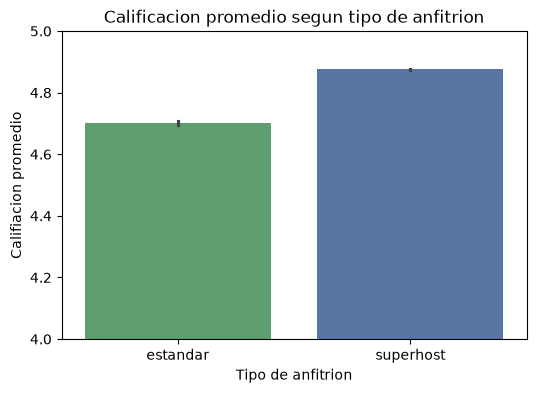

In [75]:
plt.figure(figsize=(6,4))
sns.barplot(data=df_h2, x='tipo_anfitrion', y='review_scores_rating', palette=['#55a868', '#4c72b0'])
plt.title('Calificacion promedio segun tipo de anfitrion')
plt.xlabel('Tipo de anfitrion')
plt.ylabel('Califiacion promedio')
plt.ylim(4.0, 5.0)
plt.show()

### Notamos que los superhost estan por encima de los anfitriones estandar.

### Ahora veamos como se comportan con un boxplot

/tmp/ipykernel_17238/2903090025.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_h2, x='tipo_anfitrion', y='review_scores_rating', showfliers=False, palette=['#55a868', '#4c72b0'])


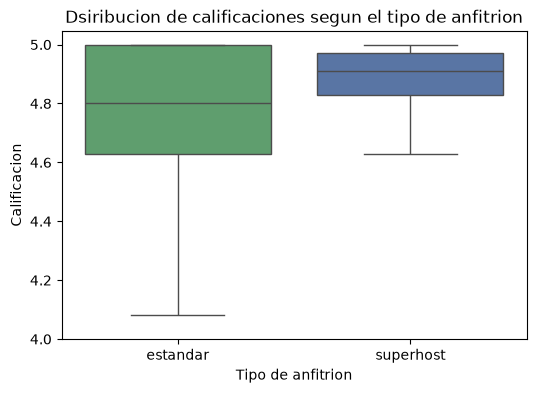

In [76]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df_h2, x='tipo_anfitrion', y='review_scores_rating', showfliers=False, palette=['#55a868', '#4c72b0'])
plt.title('Dsiribucion de calificaciones segun el tipo de anfitrion')
plt.xlabel('Tipo de anfitrion')
plt.ylabel('Calificacion')
plt.ylim(4.0)
plt.show()

### Vamos a recurrir a las pruebas estadisticas para corroborar que realmente existe esta diferencia.

### Comenzamos probando los supuestos de nomalidad y homocedasticidad.

In [77]:
superhost = df_h2[df_h2['tipo_anfitrion'] == 'superhost']['review_scores_rating']
estandar = df_h2[df_h2['tipo_anfitrion'] == 'estandar']['review_scores_rating']

#Supuesto de normalidad, utilizamos Shapiro-wilk
stat_superhost, p_val_shapiro_superhost = stats.shapiro(superhost.sample(5000, random_state=42))
stat_estandar, p_val_shapiro_estandar = stats.shapiro(estandar.sample(5000, random_state=42))

stat_levene, p_val_levene = stats.levene(superhost, estandar)

print(f"Test de normalidad para los superhost: Estadistico={stat_superhost:.3f}, p_valor={p_val_shapiro_superhost:.3f}")
print(f"Test de normalidad para los anfitriones estandar: Estadistico={stat_estandar:.3f}, p_valor={p_val_shapiro_estandar:.3f}")
print(f"Test de homocedasticidad con levene: Estadistico={stat_levene:.3f}, p_valor={p_val_levene:.3f}")


Test de normalidad para los superhost: Estadistico=0.714, p_valor=0.000
Test de normalidad para los anfitriones estandar: Estadistico=0.599, p_valor=0.000
Test de homocedasticidad con levene: Estadistico=1586.351, p_valor=0.000


### Encontramos que ambos supuestos son rechazados, en todos los casos dio p<0.05
### Vamos a hacer Kolmogorov-smirnov para despejar dudas

In [78]:
stat_ks, p = stats.kstest(superhost, 'norm')
print(f"Test de Kolmogorov-Smirnov para superhost: Estadistico={stat_ks:.3f}, p-valor={p:.3f}")

stat_ks, p = stats.kstest(estandar, 'norm')
print(f"Test de Kolmogorov-Smirnov para anfitrion estandar: Estadistico={stat_ks:.3f}, p-valor={p:.3f}")

Test de Kolmogorov-Smirnov para superhost: Estadistico=0.999, p-valor=0.000
Test de Kolmogorov-Smirnov para anfitrion estandar: Estadistico=0.989, p-valor=0.000


### Terminamos de sacarnos todas las dudas, con esto, pasamos a optar por un test no-parametrico, como lo es Mann-Whitney U

In [79]:
stat, p = stats.ttest_ind(superhost, estandar, equal_var=False, alternative='greater')
print(f"Test t con correccion de Welch: Estadistico={stat:.3f}, p-valor={p:.4e}")

stat, p = stats.mannwhitneyu(superhost, estandar, alternative='greater')
print(f"Test de Mann-Whitney U: Estadistico={stat:.3f}, p-valor={p:.4e}")

#Nivel de significancia
alpha = 0.05

if p < alpha:
    print("Se rechaza la hipotesis nula.")
    print("Los superhost tienen calificaciones sigficativamente mayores en comparacion a los anfitriones estandar")
else:
    print("No hay evidencia suficiente para rechazar la hipotesis nula")
    print("Los superhost no necesariamente tienen mejores calificaciones en comparacion a los anfitriones estandar")

Test t con correccion de Welch: Estadistico=43.316, p-valor=0.0000e+00
Test de Mann-Whitney U: Estadistico=105805671.500, p-valor=1.0188e-305
Se rechaza la hipotesis nula.
Los superhost tienen calificaciones sigficativamente mayores en comparacion a los anfitriones estandar


### Vemos que el p-valor se acerca a cero absoluto, por esto, podemos remontarnos a la hipotesis alternativa original, donde corroboramos que los superhost tienen en promedio calificacion significativamente mas alta que los anfitriones estandar.
### Como ultimo dato, vamos a mostrar las medias y medianas, y la diferencia.

In [80]:
media_superhost=superhost.mean()
media_estandar=estandar.mean()
mediana_superhost=superhost.median()
mediana_estandar=estandar.median()

print(f"Superhost - Media: {media_superhost:.3f} | Mediana: {mediana_superhost:.3f}")
print(f"Anfitrion Estandar - Media: {media_estandar:.3f} | Mediana: {mediana_estandar:.3f}")
print(f"Diferencia de calificacion: {media_superhost - media_estandar:+.2f}")

Superhost - Media: 4.875 | Mediana: 4.910
Anfitrion Estandar - Media: 4.702 | Mediana: 4.800
Diferencia de calificacion: +0.17


## Hipótesis multivariada

**Hipótesis:** a igual capacidad, tipo de alojamiento y barrio, los
alojamientos que exigen estadías mínimas más largas cobran un precio por
noche menor.

**Justificación:** un host que exige estadías largas se parece más a un
alquiler tradicional que a uno turístico, y suele compensar con un descuento
por noche a cambio de una ocupación más estable. Para comparar, agrupamos la
estadía mínima en tres categorías según cómo se usa el alojamiento: corta
(1 a 6 noches: escapadas y fines de semana largos), media (7 a 29: vacaciones
de una o dos semanas, y algo más) y larga (30 o más: alquiler mensual,
cercano al tradicional). Los cortes se definieron por el uso habitual del
mercado y no según los resultados, y coinciden con valores muy frecuentes de
la base (7 y 30 noches).

In [81]:
analisis_modelo["minimum_nights"] = dataset_limpio["minimum_nights"]

analisis_modelo["estadia"] = pd.cut(analisis_modelo["minimum_nights"],
                                    bins=[0, 6, 29, float("inf")],
                                    labels=["corta (1-6)", "media (7-29)", "larga (30+)"])

analisis_modelo["estadia"].value_counts()

estadia
corta (1-6)     20685
media (7-29)     1900
larga (30+)       339
Name: count, dtype: int64

### Modelo de estadía mínima

Ajustamos una regresión lineal sobre el precio con el grupo de estadía mínima como variable principal, controlando por capacidad, tipo de alojamiento y barrio. Tomamos como referencia la estadía corta (1 a 6 noches) para ver la diferencia de precio con las estadías más largas.

In [82]:
modelo_est = smf.ols("precio ~ C(estadia) + accommodates + C(room_type) + C(barrio)",
                     data=analisis_modelo).fit()

tabla = pd.DataFrame({"coef": modelo_est.params, "p-valor": modelo_est.pvalues})
print("R²:", round(modelo_est.rsquared, 3), "| observaciones:", int(modelo_est.nobs))
tabla[tabla.index.str.contains("estadia|accommodates|room_type")].round(4)

R²: 0.325 | observaciones: 22924


,coef,p-valor
C(estadia)[T.media (7-29)],-17907.0570,0.0
C(estadia)[T.larga (30+)],-32162.1155,0.0
C(room_type)[T.Hotel room],59675.5782,0.0
C(room_type)[T.Private room],-25696.1416,0.0
C(room_type)[T.Shared room],-59398.9860,0.0
accommodates,14521.5974,0.0


### Supuestos del modelo de estadía mínima

Revisamos los supuestos del modelo: que no haya multicolinealidad entre variables (VIF), cómo se distribuyen los residuos (gráfico de dispersión) y su normalidad (Q-Q plot y Jarque-Bera).

In [83]:
base = analisis_modelo.dropna(subset=["estadia"])
X = pd.get_dummies(base[["estadia", "room_type"]], drop_first=True).astype(float)
X["accommodates"] = base["accommodates"]
X = add_constant(X)

vif = pd.DataFrame({"variable": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif[vif["variable"] != "const"].round(2)

,variable,VIF
1,estadia_media (7-29),1.01
2,estadia_larga (30+),1.00
3,room_type_Hotel room,1.00
4,room_type_Private room,1.06
5,room_type_Shared room,1.00
6,accommodates,1.06


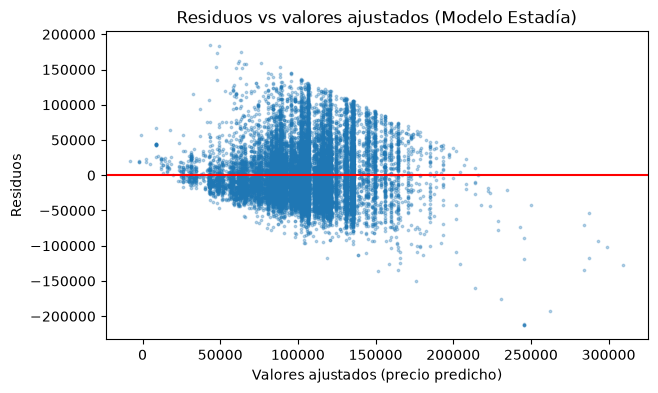

In [84]:
plt.figure(figsize=(7, 4))
plt.scatter(modelo_est.fittedvalues, modelo_est.resid, s=3, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados (precio predicho)")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados (Modelo Estadía)")
plt.show()

Test de Jarque-Bera: Estadístico = 4355.76, p-valor = 0.0000e+00


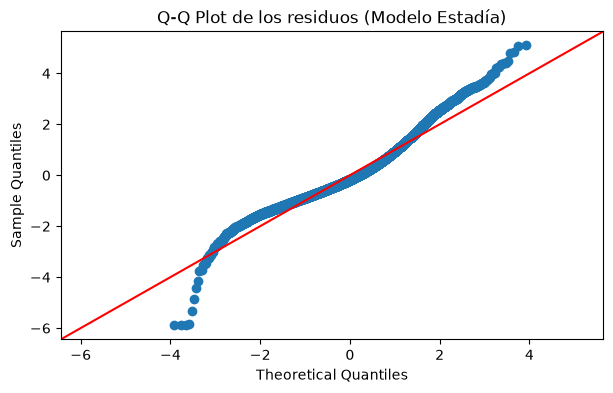

In [85]:
# Evaluación de normalidad sin submuestreo: Jarque-Bera y Q-Q Plot
jb_stat_est, jb_p_est, skew_est, kurt_est = sm.stats.stattools.jarque_bera(modelo_est.resid)
print(f"Test de Jarque-Bera: Estadístico = {jb_stat_est:.2f}, p-valor = {jb_p_est:.4e}")

fig, ax = plt.subplots(figsize=(7, 4))
sm.qqplot(modelo_est.resid, line="45", fit=True, ax=ax)
ax.set_title("Q-Q Plot de los residuos (Modelo Estadía)")
plt.show()

El comportamiento es similar al modelo anterior: no hay multicolinealidad, la varianza de los residuos se mantiene pareja en la mayor parte de los datos y, aunque hay desvíos en los precios más altos, la cantidad de observaciones permite confiar en los resultados.

### Independencia de los errores (Durbin-Watson)

Para ver si los errores son independientes entre sí, miramos el estadístico de Durbin-Watson en ambos modelos. Como da un valor cercano a 2, confirma que no hay autocorrelación en los residuos y que el supuesto se cumple bien.

In [86]:
from statsmodels.stats.stattools import durbin_watson

dw_modelo2 = durbin_watson(modelo2.resid)
dw_modelo_est = durbin_watson(modelo_est.resid)

print(f"Durbin-Watson Modelo 2 (Hipótesis C): {dw_modelo2:.4f}")
print(f"Durbin-Watson Modelo Estadía Mínima:   {dw_modelo_est:.4f}")

Durbin-Watson Modelo 2 (Hipótesis C): 1.7455
Durbin-Watson Modelo Estadía Mínima:   1.7597


In [87]:
# Tabla resumen de diagnósticos según los criterios de la cátedra (Clase 9)
resumen_diagnosticos = pd.DataFrame({
    "Métrica / Diagnóstico": ["R²", "Durbin-Watson (Independencia DW ≈ 2)", "Jarque-Bera (p-valor)", "N Observaciones"],
    "Modelo 2 (Hipótesis C)": [
        f"{modelo2.rsquared:.3f}",
        f"{dw_modelo2:.3f}",
        f"{jb_pvalor:.2e}",
        int(modelo2.nobs)
    ],
    "Modelo Estadía Mínima": [
        f"{modelo_est.rsquared:.3f}",
        f"{dw_modelo_est:.3f}",
        f"{jb_p_est:.2e}",
        int(modelo_est.nobs)
    ]
})
resumen_diagnosticos

,Métrica / Diagnóstico,Modelo 2 (Hipótesis C),Modelo Estadía Mínima
0,R²,0.310,0.325
1,Durbin-Watson (Independencia DW ≈ 2),1.746,1.760
2,Jarque-Bera (p-valor),0.00e+00,0.00e+00
3,N Observaciones,22927,22924


### Conclusión de la hipótesis multivariada

Queríamos ver si los alojamientos que piden estadías mínimas más largas cobran más barato por noche. Con la regresión encontramos:
- **Estadía media (7 a 29 noches):** cobra menos por noche que la estadía corta, y la diferencia es estadísticamente significativa.
- **Estadía larga (30 noches o más):** tiene una rebaja por noche todavía más grande, también significativa.

Además, los residuos dan independientes (Durbin-Watson cercano a 2). Por lo tanto, la hipótesis se confirma: a mayor estadía mínima exigida, menor es el precio por noche.

Como detalle a tener en cuenta, en los datos se ve que varios alojamientos pertenecen al mismo anfitrión, lo que refleja cómo funciona la oferta en la plataforma.

# SECCION 3: Hipotesis planteadas y sus validaciones.

## Hipotesis A
**Hipotesis planteada:** Mas del 60% de la oferta la controlan agencias multipropiedad, no personas alquilando su propio hogar.

**Consideracion inicial:** Tuvimos la disyuntiva de como abordar el termino multipropiedad, optamos por lo que nos parecio la mejor opcion, utilizar el termino multi-listing
utilizado por 'Inside airbnb', el cual toma como multipropiedad a aquellos host que poseen 2 o mas propiedades en alquiler.

### Lo primero que hicimos fue crear un nuevo dataframe con las columnas que nos iban a ser de utilidad.

In [88]:
dfA=dataset_limpio[["host_id", "calculated_host_listings_count"]]
dfA.describe()


,host_id,calculated_host_listings_count
count,2.968500e+04,29685.000000
mean,1.081103e+16,15.194240
std,1.347071e+17,32.782011
min,1.342600e+04,1.000000
25%,3.506745e+07,1.000000
50%,1.585246e+08,3.000000
75%,4.644293e+08,12.000000
max,1.716955e+18,208.000000


In [89]:
dfA.count()

host_id                           29685
calculated_host_listings_count    29685
dtype: int64

In [90]:
cuenta = dfA["host_id"].value_counts()
filtered = cuenta[cuenta > 1]
print("Multipropiedad: ", filtered.count(), "Personales: ", cuenta.count()-filtered.count())

Multipropiedad:  3748 Personales:  10808


### De entrada, vemos que la cantidad de listadores con mas de 1 propiedad en dispocicion es casi un tercio de las propiedaes alquiladas por sus propios dueños. Esto aun no nos indica nada, pero teniendo en cuenta que hay aproximadamente 29000 publicaciones, sabemos que ~10000 son de propietario unico, por ende menor.
### A continuacion vamos utilizar un metodo grafico para poder ver esta comparacion de manera clara.

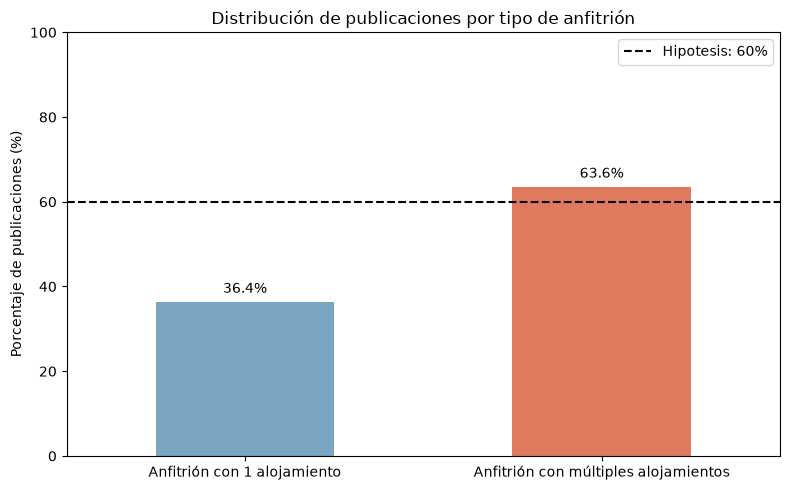

In [91]:
# Porcentaje de publicaciones según si el anfitrión ofrece más de un alojamiento
cuenta = dfA["host_id"].value_counts()
publicaciones = pd.Series({
    "Anfitrión con 1 alojamiento": cuenta[cuenta == 1].sum(),
    "Anfitrión con múltiples alojamientos": cuenta[cuenta > 1].sum(),
})
porcentaje_publicaciones = publicaciones / publicaciones.sum() * 100

#Porcentaje_publicaciones consta con el porcentaje real de publicaciones por sobre la cantidad de publicaciones listadas.

ax = porcentaje_publicaciones.plot(kind="bar", figsize=(8, 5), color=["#7aa6c2", "#e07a5f"])
ax.axhline(60, color="black", linestyle="--", linewidth=1.5, label="Hipotesis: 60%")
ax.set_title("Distribución de publicaciones por tipo de anfitrión")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje de publicaciones (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for barra, valor in zip(ax.patches, porcentaje_publicaciones):
    ax.annotate(f"{valor:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")

plt.tight_layout()
plt.show()

### Con este grafico podemos visualizar claramente que la hipotesis,a primera vista, se cumple, ya que mas de el 60% de publicaciones listadas son gestionadas por agencias multipropiedad, ahora chequearemos si las cuentas dicen lo mismo.

### Ahora vamos a la parte estadistica, planteo de Hipotesis y su validacion veridica.

In [92]:
#Datos obetnidos
total = dfA["host_id"].count()
uni_pub = cuenta[cuenta ==1].sum()
multi_pub = total - uni_pub

print("Total de publicaciones:", total)
print("Publicaciones personales:", uni_pub)
print("Publicaciones de agencia multipropiedad:", multi_pub)

Total de publicaciones: 29685
Publicaciones personales: 10808
Publicaciones de agencia multipropiedad: 18877


### Separamos por tipo de propietario, y obvservamos la cantidad respectiva a cada uno, para conocer los numeros exactos.

### VALIDACION CON TEST

In [ ]:
#Tomando como multipropiedad a aquellos publicadores con MAS de 1 publicacion, vamos a hacer encoding para
#definir una nueva columna en el dataset que nos permita identificar a los publicadores de multipropiedad y a los publicadores personales.
 
#Primero haremos encoding para definir con booleanos si el publicador es de multipropiedad o no. Esto da como resultado el analisis de una variable cualitativa nominal dicotomica.
dfA["multipropiedad"] = dfA["host_id"].apply(lambda x: True if x in filtered.index else False)
print("Proporcion de agentes multipropiedad", round(dfA["multipropiedad"].mean()*100, 2), "%")
print("Valores nulos en la columna de multipropiedad:", dfA["multipropiedad"].isna().sum())
print("Total de filas en el dataset:", len(dfA))

KeyError: 'multiprpiedad'

In [ ]:
#Frecuencia absoluta
frec_abs = dfA["multipropiedad"].value_counts()

#Frecuencia relativa
frec_rel = dfA["multipropiedad"].value_counts(normalize=True)

#Tabla para poder analizar
tabla = pd.DataFrame({"Categoria": ["Unipropiedad", "Multipropiedad"], "Frecuencia absoluta": frec_abs, "Frecuencia relativa": frec_rel})

print(tabla)
p_sombrero=dfA["multipropiedad"].mean()
print(f"\nProporcion Mmuestral (media p_sombrero): {p_sombrero:.4f} ({p_sombrero*100:.2f}%)")

                     Categoria  Frecuencia absoluta  Frecuencia relativa
multipropiedad                                                          
True              Unipropiedad                18877              0.63591
False           Multipropiedad                10808              0.36409

Proporcion Mmuestral (media p_sombrero): 0.6359 (63.59%)


#### Lo anteriormente calculado ya nos da un pie a que la hipotesis es verdadera, ya que, analiticamente vemos que la media corresponde al ~63.59%

In [ ]:
#Hipotesis nula: p0 <= 0.6 (60%)
#Hipotesis alternativa: p0 > 0.6 (60%)


#Test t para comparar la proporcion muestral con la proporcion poblacional (hipotesis nula)
from scipy.stats import ttest_1samp

p0 = 0.6 #Hipotesis nula
t_stat, p_value = ttest_1samp(dfA["multipropiedad"], p0, alternative='greater')

print(f"\nEstadistico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.4e}")

alpha = 0.05 # Nivel de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: La proporción de multipropiedad es significativamente mayor que 60%.")
    print("Se puede afirmar que la proporción de multipropiedad es mayor que 60%.")
else:
    print("No se puede rechazar la hipótesis nula: No hay evidencia suficiente para afirmar que la proporción de multipropiedad es mayor que 60%.")




Estadistico t: 12.8582
Valor p: 4.8802e-38
Rechazamos la hipótesis nula: La proporción de multipropiedad es significativamente mayor que 60%.
Se puede afirmar que la proporción de multipropiedad es mayor que 60%.


### Con este estadistico confirmamos que la muestra se encuentra casi 13 desviaciones estandar de la hipotesis y el p-valor es menor a 0.05, por ende, se acepta la hipotesis de >60% y confirmamos que en el mercado de airbnb, teniendo en cuenta la consideracion inicial sobre el multi-listing, mas del 60% de las viviendas publicadas, pertenecen a agentes multipropiedad.

//BIVARIADAS

## Hipotesis B
**Hipotesis planteada:** Alquilar un espacio entero cuesta, en promedio, mas del doble que alquilar una habitacion privada.

In [ ]:
dfB = dataset_limpio[["price_quote_price_per_night", "room_type"]]
dfB = dfB.rename(columns={"price_quote_price_per_night": "precio"})
print(dfB.head(10))

                        precio        room_type
id                                             
54019695              86206.29  Entire home/apt
41720307              74564.86  Entire home/apt
1090530711732696379  514309.14  Entire home/apt
1482653002662185299  144486.00  Entire home/apt
1046394538968941382   25317.00     Private room
1708343918490071398   60746.92  Entire home/apt
1097705859760051456        NaN  Entire home/apt
1481532845124538775   60875.33     Private room
568894083555155106   343348.29  Entire home/apt
1584290581776571173   78287.22     Private room


### Usamos 'price_quote_price_per_night' ya que la columna default 'price' es de tipo sring, y ademas aca ya se encuentra realizada la conversion correspondiente, sin alterar valores
### Le cambiamos el nombre a 'precio' para que sea mas facil a la hora de trabajar y visualizar datos.

In [ ]:
dfB.isna().sum()

price        1792
room_type       0
dtype: int64

In [ ]:
dfB.info()

<class 'pandas.DataFrame'>
Index: 29685 entries, 54019695 to 994057877545566961
Data columns (total 3 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   price_quote_price_per_night  27893 non-null  float64
 1   price                        27893 non-null  str    
 2   room_type                    29685 non-null  str    
dtypes: float64(1), str(2)
memory usage: 927.7 KB


In [ ]:
dfB["room_type"].value_counts()

room_type
Entire home/apt    26790
Private room        2616
Hotel room           141
Shared room          138
Name: count, dtype: int64

In [ ]:
nulos = dfB.groupby("room_type")["precio"].agg(total_filas = 'size', total_nulos = lambda x: x.isna().sum(), porcentajes = lambda x: round(x.isna().mean()*100, 2))
nulos

,total_filas,total_nulos,porcentajes
room_type,,,
Entire home/apt,26790,1649,6.16
Hotel room,141,5,3.55
Private room,2616,131,5.01
Shared room,138,7,5.07


### Viendo esto tenemos la siguiente situacion:
### -La columna 'price' se encuentra como string, por ende, para calcular promedios, debemos usar 'price_quote_price_per_night' la cual contiene el mismo dato cuantitativo continuo, pero representado en float64.
### -Existen 1792 registros con 'price' vacio.
### -Los espacios enteros y las habitaciones privadas, cuentan con el 6,16% y 5,01%, respectivamente, de datos nulos en la columna 'price'
### -Notamos una relacion 10:1 entre las cantidades de registros para 'Entire home/apt' y 'private room'.

In [ ]:
dfB.info()

<class 'pandas.DataFrame'>
Index: 29685 entries, 54019695 to 994057877545566961
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   price      27893 non-null  float64
 1   room_type  29685 non-null  str    
dtypes: float64(1), str(1)
memory usage: 695.7 KB


In [ ]:
dfB["precio"].describe().apply(lambda x: f"{x:.2f}")

count        27893.00
mean        275831.94
std        3622301.98
min           1215.50
25%          75274.57
50%         100631.33
75%         140480.93
max      171643781.00
Name: precio, dtype: str

### Viendo este describe ya notamos presencias de fuertes outliers, que quiza nos condicionan la hipotesis.

### Borrado de las filas que contienen 'precio' con NaN.

In [ ]:
dfB = dfB.dropna(subset=["precio"]).copy()
print("Cantidad de nulos en 'price':",dfB["precio"].isna().sum())
print("Cantidad de datos luego del borrado:",len(dfB))
print("Cantidad de datos por tipo de alquiler: ", dfB["room_type"].value_counts())

Cantidad de nulos en 'price': 0
Cantidad de datos luego del borrado: 27893
Cantidad de datos por tipo de alquiler:  room_type
Entire home/apt    25141
Private room        2485
Hotel room           136
Shared room          131
Name: count, dtype: int64


/home/matilinux/Ciencia-De-Datos/TP_Fundamentos/TP_Fundamentos/TpEspecial/venvTPE/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Feature: precio                              |███▎      | [ 33%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find fon


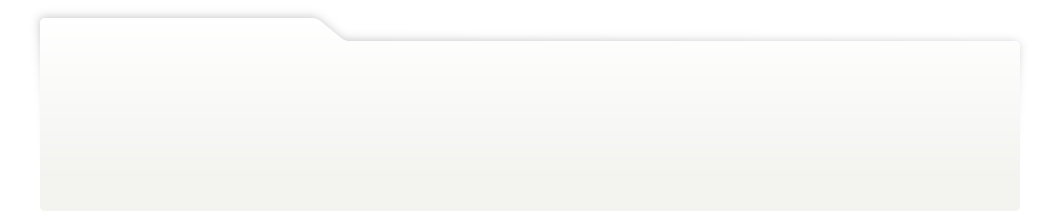
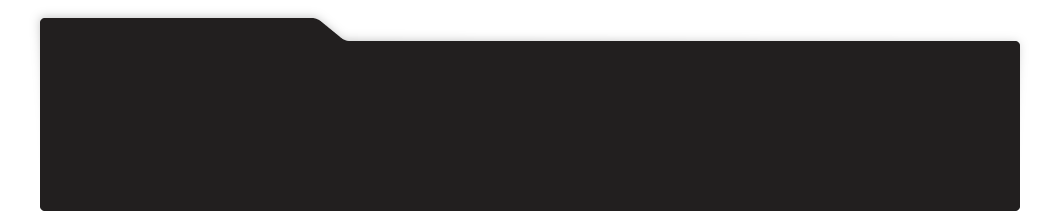
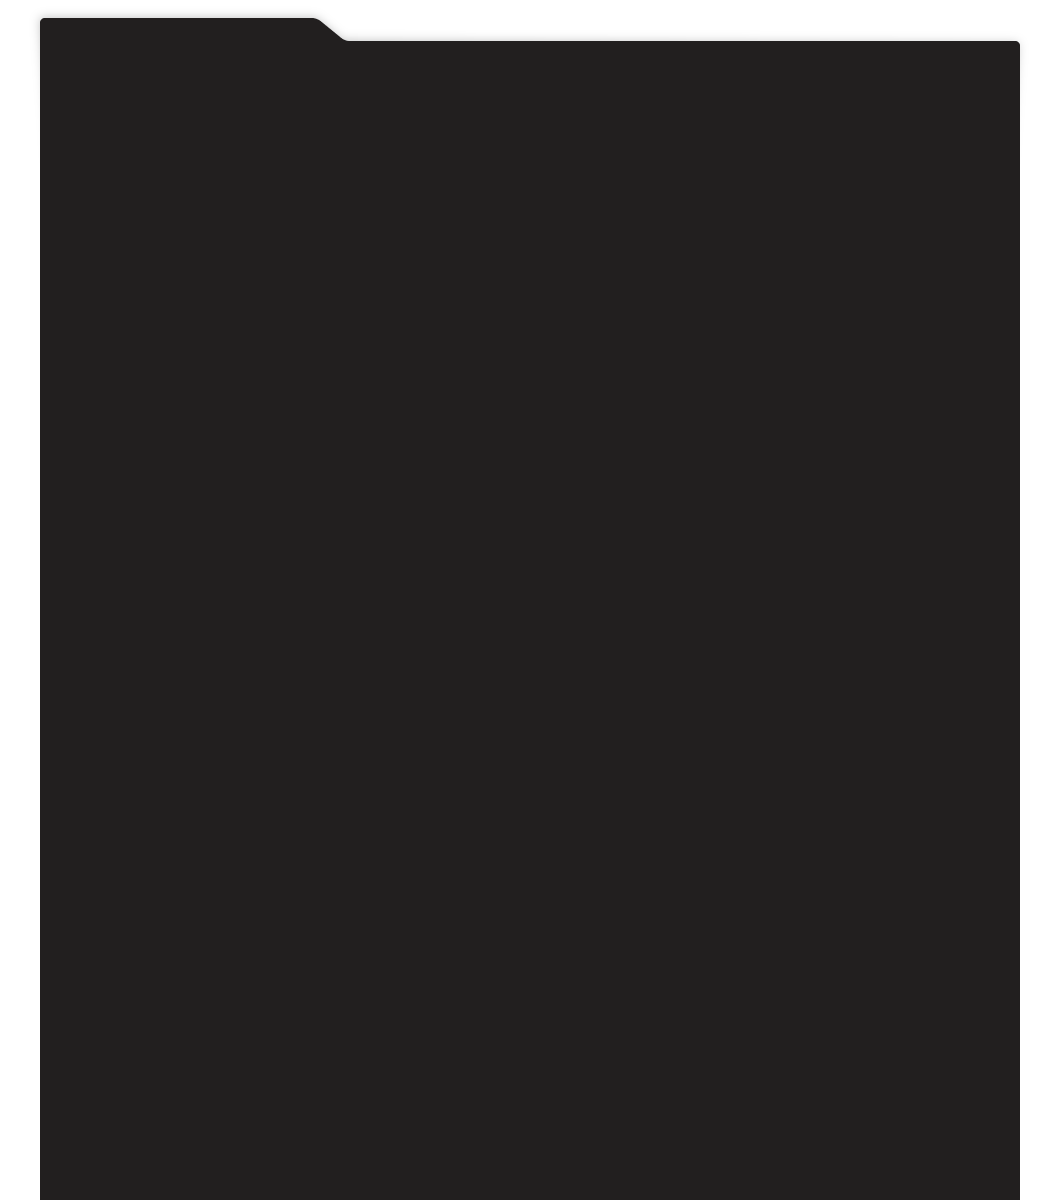
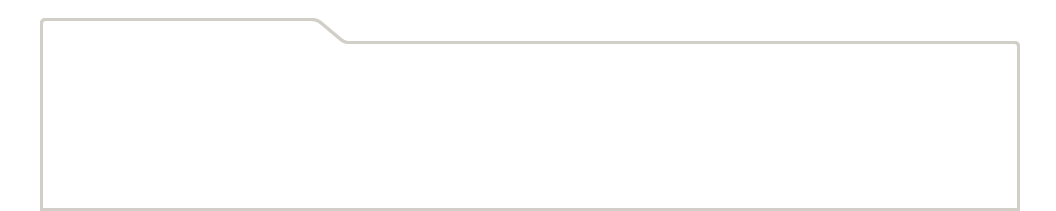
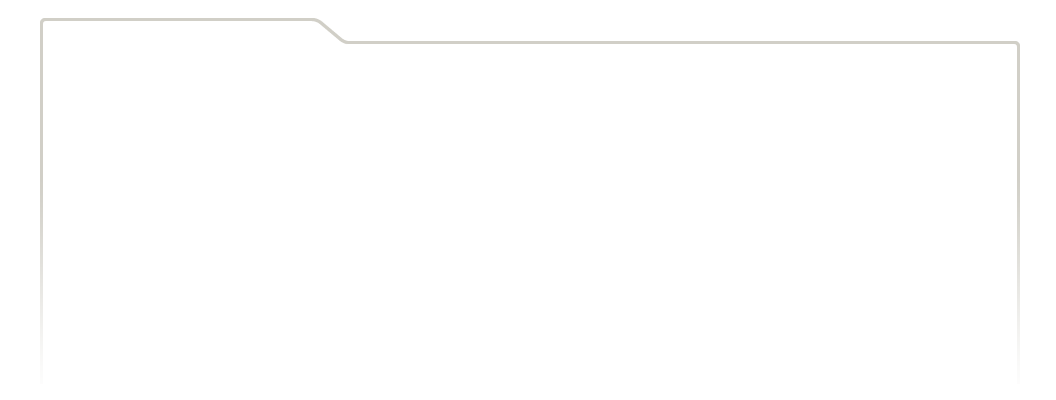
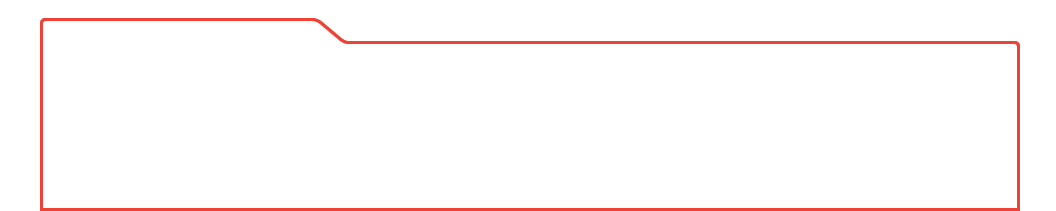
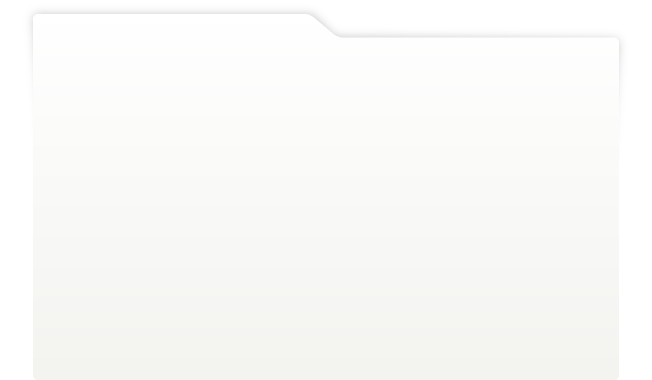
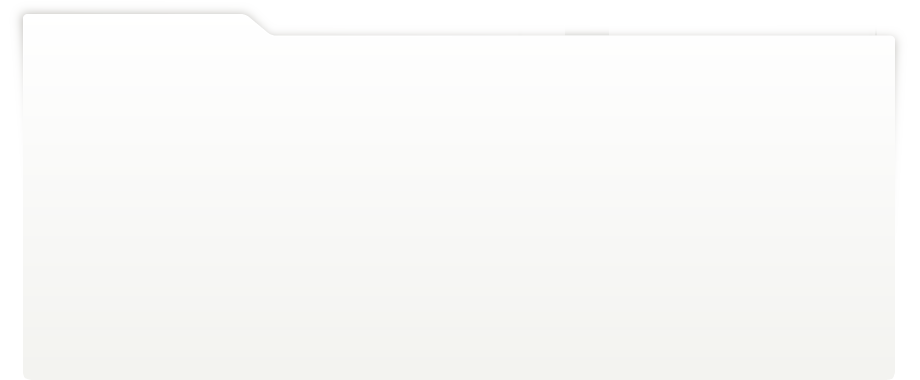
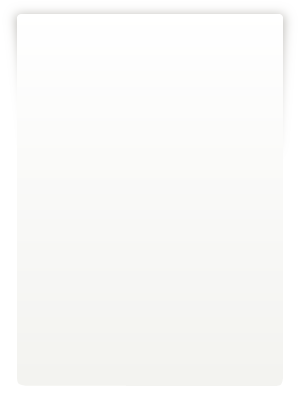
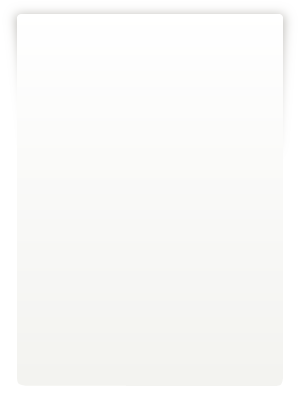
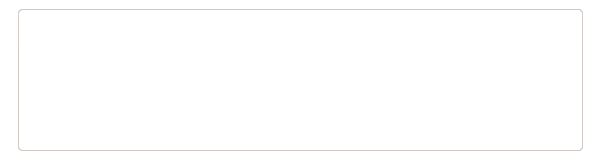
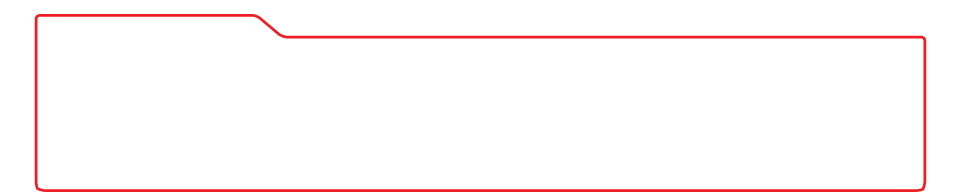
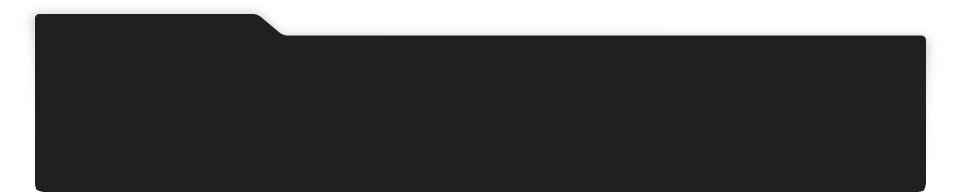
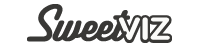
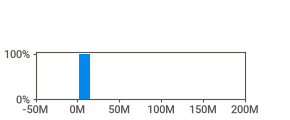
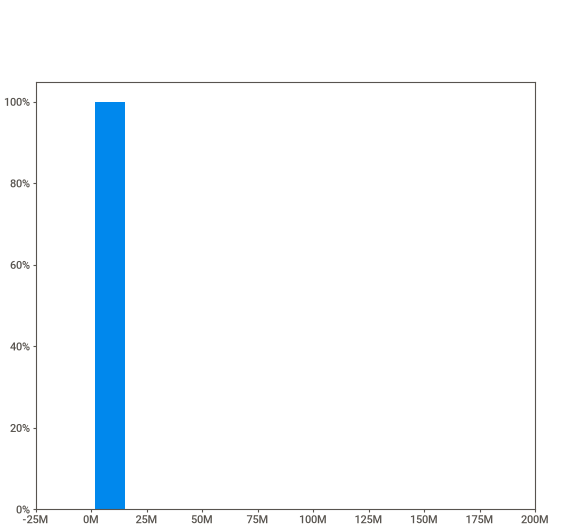
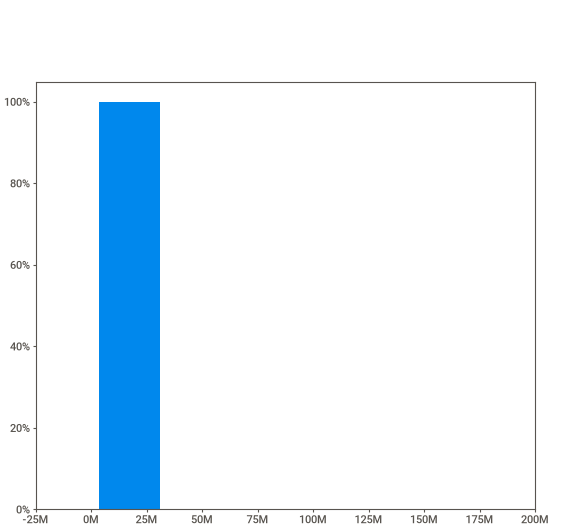
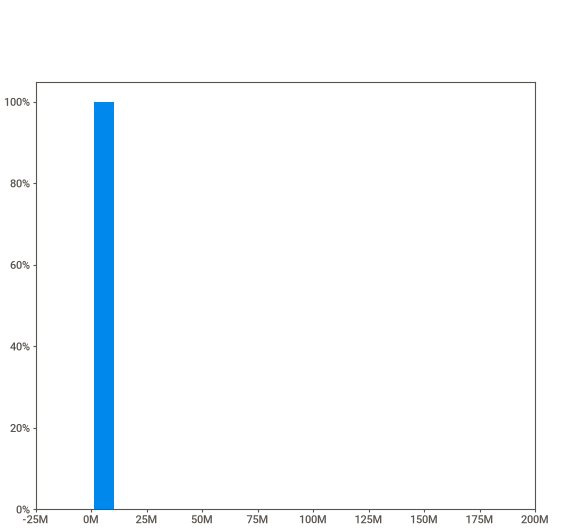
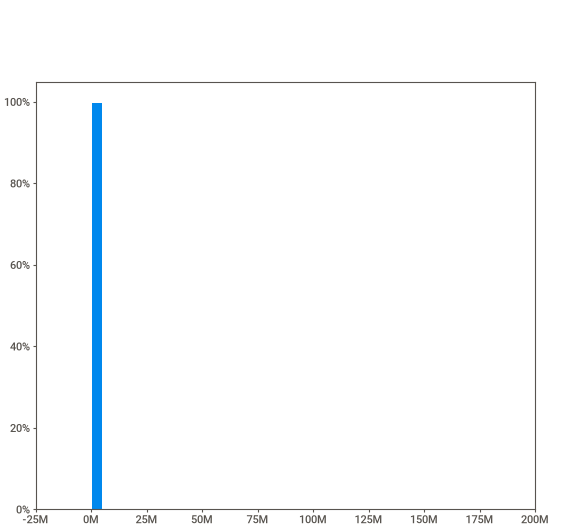
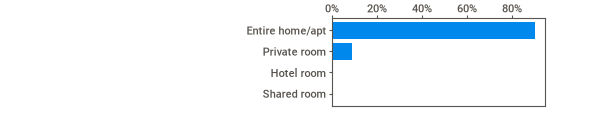
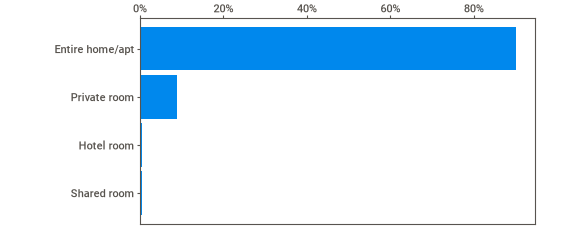
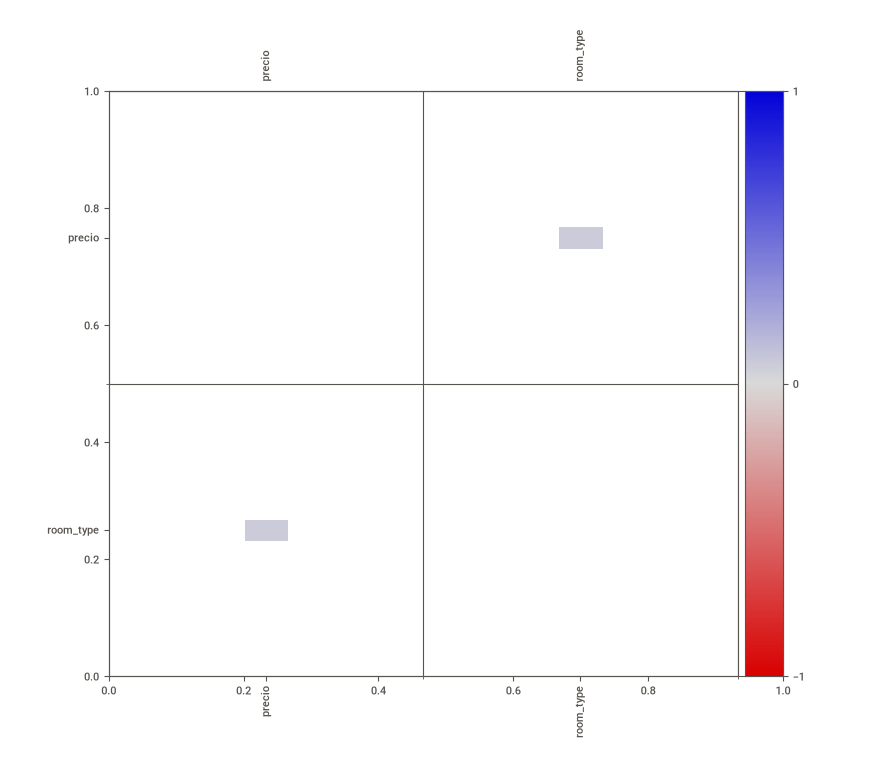
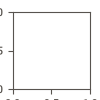

In [ ]:
import sweetviz as sv

reporte = sv.analyze(dfB)
reporte.show_notebook()

### Con esto logramos ver que, la presencia de ouliers y duplicados es elevada, notamos que en el 95% el precio es de 0,3 millones de pesos (300mil) pero que el valor maximo alcanza los 170 millones. Con duplicados notamos que hay un 69% de filas unicas, por ende, aproximadamente un 31% de duplicados, lo cual es alto.

### Vamos a indagar sobre duplicados.

In [ ]:
print("Cantidad de filas duplicadas:", dfB.duplicated().sum())

Cantidad de filas duplicadas: 8029


### Vemos que la cantidad de duplicados es alta, pero esto puede deberse a que existan alquileres con exacto mismo precio y tipo de habitacion. Por esto vamos a sacarnos la duda utilizando los atributos 'latitude' y 'longitude'.

In [ ]:
duplicados = dfB.join(dataset_limpio[["latitude", "longitude"]])
print("Cantidad de duplicados utilizando coordenadas del alquiler", duplicados.duplicated().sum())
print("Porcentaje duplicados reales: ", round((duplicados.duplicated().sum()/ len(dfB))*100,2) , "%")

Cantidad de duplicados utilizando coordenadas del alquiler 249
Porcentaje duplicados reales:  0.89 %


In [ ]:
# Chequeamos con todas las columnas originales, para despejar todas las dudas
print("Cantidad de filas duplicadas con todas las columnas:", dataset_limpio.duplicated().sum())

Cantidad de filas duplicadas con todas las columnas: 5


### Con esto dejamos en claro que los duplicados que ya habiamos encontrado eran simplemente coincidencias de tipo y precio. Por ende, no se modificaran o eliminaran filas duplicadas, ya que, los duplicados reales representan menos del 1% de la muestra. Seguimos trabajando con el datafram 'dfB'.

### A continuacion dejamos un resumen del EDA para los tipos de alquiler

In [ ]:
import scipy.stats as stats
def resumen_eda(df, col_grupo, col_valor):
    filas=[]
    for grupo,sub in df.groupby(col_grupo):
        s = sub[col_valor]
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr
        outliers = ((s<limite_inf) | (s>limite_sup)).sum()
        resumen={
            'Grupo': grupo,
            'n': len(s),
            'Media': s.mean(),
            'Mediana': s.median(),
            'Desv. Est.': s.std(),
            'IQR': iqr,
            'CV (%)': (s.std(ddof=1)/s.mean())*100,
            'Asimetria': stats.skew(s, bias=False),
            'Curtosis': stats.kurtosis(s, bias=False),
            'Outliers': outliers,
            '% Outliers': (outliers/len(s))*100
        }
        filas.append(resumen)

    return pd.DataFrame(filas).round(2)

tabla_eda = resumen_eda(dfB, 'room_type', 'precio')
print(tabla_eda.to_string(index=False))

          Grupo     n     Media  Mediana  Desv. Est.       IQR  CV (%)  Asimetria  Curtosis  Outliers  % Outliers
Entire home/apt 25141 254476.12 103977.0  3199412.01  63784.17 1257.25      32.15   1147.17      2089        8.31
     Hotel room   136 226311.80 222895.5   103051.50 139138.75   45.54       0.15     -0.00         0        0.00
   Private room  2485 500523.15  51002.0  6600215.16  45015.71 1318.66      17.38    331.70       205        8.25
    Shared room   131 163495.94  25405.0  1476709.39  21127.91  903.21      11.44    130.94         9        6.87


In [ ]:
def resumen_eda_sin_outliers(df, col_grupo, col_valor):
    filas=[]
    for grupo,sub in df.groupby(col_grupo):
        q1 = sub[col_valor].quantile(0.25)
        q3 = sub[col_valor].quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr
        sub_limpio = sub[(sub[col_valor]>=limite_inf) & (sub[col_valor]<=limite_sup)]
        filas.append(sub_limpio)
        print(f"{grupo}: limite superior de tukey: {limite_sup:,.2f} |" 
              f"Outliers eliminados: = {len(sub) - len(sub_limpio)} ({((len(sub) - len(sub_limpio))/len(sub))*100:.2f}%)")

    return pd.concat(filas,ignore_index=True)

dfB_sin_outliers = resumen_eda_sin_outliers(dfB, 'room_type', 'precio')
tabla_sin_ol = resumen_eda(dfB_sin_outliers, 'room_type', 'precio')

print(tabla_sin_ol.to_string(index=False))

Entire home/apt: limite superior de tukey: 239,617.76 |Outliers eliminados: = 2089 (8.31%)
Hotel room: limite superior de tukey: 515,927.38 |Outliers eliminados: = 0 (0.00%)
Private room: limite superior de tukey: 147,679.03 |Outliers eliminados: = 205 (8.25%)
Shared room: limite superior de tukey: 74,081.28 |Outliers eliminados: = 9 (6.87%)
          Grupo     n     Media   Mediana  Desv. Est.       IQR  CV (%)  Asimetria  Curtosis  Outliers  % Outliers
Entire home/apt 23052 107769.92  99670.63    42243.89  52450.22   39.20       0.81      0.43       665        2.88
     Hotel room   136 226311.80 222895.50   103051.50 139138.75   45.54       0.15     -0.00         0        0.00
   Private room  2280  55170.75  48116.00    27933.63  34855.04   50.63       1.04      0.64        76        3.33
    Shared room   122  30185.49  25317.00    13582.78  15344.50   45.00       1.04      0.15         6        4.92


### Limpiando los outliers utilizando el rango interquartilico, notamos que ahora las media y mediana son mas acordes entre si. Los outliers de este dataset pueden estar por diversas razones, tanto precios mal cargados, como precios altos para congelar el alquiler (Ejemplo: Un alquiler de espacio completo tenia como precio aproximadamente 170 millones la noche, este lo podemos tomar como un outlier extremo, el cual, casi con certeza, es un valor que no refleja nada real).

### Ahora vemos que la Media de espacios enteros es menos de 2 veces mayor a la Media de las habitaciones privadas (107769 < 2x55170). Y con la mediana, donde para los espacios enteros es de 99670, mientras que la de las habitaciones privadas es de 48116, la diferencia es de menos del doble (99670 > 2x48116).

### Con esto hecho, se tomo la decision de utilizar dfB_sin_outliers, este dataframe esta limpio de los outliers que nos afectaban las estadisticas previas.

In [ ]:
dfB_sin_outliers.describe()

,precio
count,25590.000000
mean,103343.589714
std,45433.944016
min,1215.500000
25%,72987.640000
50%,95960.995000
75%,126963.500000
max,509213.330000


/tmp/ipykernel_4763/2521041088.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Tipo",
findfont: Failed to find font weight normal for Roboto, now using 500.


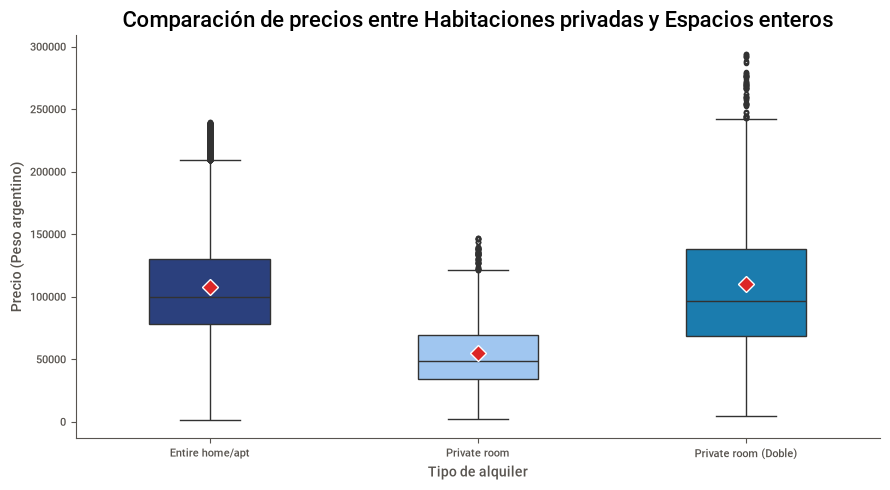

In [ ]:
df_espacio_entero = pd.DataFrame({
    "Tipo": "Entire home/apt",
    "Precio": dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Entire home/apt", "precio"]
})
df_habitacion_privada = pd.DataFrame({
    "Tipo": "Private room",
    "Precio": dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Private room", "precio"]
})
df_habitacion_privada_doble = pd.DataFrame({
    "Tipo": "Private room (Doble)",
    "Precio": df_habitacion_privada["Precio"] * 2
})

df_box = pd.concat([df_espacio_entero, df_habitacion_privada, df_habitacion_privada_doble], ignore_index=True)

plt.figure(figsize=(9, 5))

sns.boxplot(x="Tipo", 
            y="Precio", 
            data=df_box, 
            palette=["#1e3a8a", "#93c5fd", "#0284c7"], 
            width=0.45, 
            showmeans=True, 
            meanprops={"marker": "D", "markerfacecolor": "#dc2626", "markeredgecolor": "white", "markersize": 8, "label": "Media"})

plt.title("Comparación de precios entre Habitaciones privadas y Espacios enteros", fontsize=16)
plt.xlabel("Tipo de alquiler")
plt.ylabel("Precio (Peso argentino)")
sns.despine()
plt.tight_layout()
plt.show()

### Lo que notamos visualmente es que, la mediana (Q2) de los espacios enteros se encuentra levemente por encima del doble de las habitaciones privadas, mientras que con la media (El rombo rojo dentro del box) ocurre al reves, la media de los espacios enteros esta levemente por debajo del doble de las habitaciones privadas.

### Vamos a dar paso los test para poder validar o rechazar la hipotesis de forma precisa.

### Test de shapiro-wilk para chequear normalidad:

In [ ]:

#Separamos entre espacio entero y habitacion privada
y_espacio_entero = dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Entire home/apt", "precio"]
y_habitacion_privada = dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Private room", "precio"]
y_habitacion_privada_doble = df_habitacion_privada["Precio"] * 2

#Test de shapiro-wilk para verificar normalidad
stat, p = stats.shapiro(y_espacio_entero)
print(f"Shapiro-Wilk test para 'Entire home/apt': estadístico={stat:.4f}, p-valor={p:.4e}")

stat, p = stats.shapiro(y_habitacion_privada)
print(f"Shapiro-Wilk test para 'Private room': estadístico={stat:.4f}, p-valor={p:.4e}")

Shapiro-Wilk test para 'Entire home/apt': estadístico=0.9533, p-valor=1.0842e-63
Shapiro-Wilk test para 'Private room': estadístico=0.9186, p-valor=2.1405e-33


/home/matilinux/Ciencia-De-Datos/TP_Fundamentos/TP_Fundamentos/TpEspecial/venvTPE/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23052.
  res = hypotest_fun_out(*samples, **kwds)


### Con esto rechazamos normalidad ya que ambos para ambos p no se cumple p > 0,05
### Ahora vamos a utilizar levene para chequear homocedasticidad.

In [ ]:
stat, p = stats.levene(y_espacio_entero, y_habitacion_privada_doble)
print(f"Test de Levene: Estadistico={stat:.4f}, p-valor={p:.4e}")

Test de Levene: Estadistico=247.5967, p-valor=1.5906e-55


### ¿Que es lo que observamos? Se rechazan lo supuestos de normalidad y homocedasticidad, por ende, vamos a utilizar un test no parametrico para hacer la validacion.

Recurrimos al test de la mediana

In [ ]:
#Definimos un nivel de significancia para el test.
alpha = 0.05

stat_chi2, p_val_mediana, mediana_global, tabla_contingencia = stats.median_test(y_espacio_entero, y_habitacion_privada_doble)

print(f"Mediana de 'entire home/apt': {y_espacio_entero.median():.2f}")
print(f"Mediana de 'private room': {y_habitacion_privada.median():.2f}")
print(f"Mediana doble de 'private room': {y_habitacion_privada_doble.median():.2f}")
print(f"Mediana global: {mediana_global:.2f}")
print(f"Estadistico chi-cuadrado: {stat_chi2:.4f}")
print(f"Valor p: {p_val_mediana:.4e}")

tabla_dfB = pd.DataFrame(tabla_contingencia, index=["Mayores a la mediana global", "Menores o iguales a la mediana global"], columns=["Entire home/apt", "2 x Private room"])
print("\nTabla de contingencia respecto a la mediana global: ")
print(tabla_dfB)

if p_val_mediana < alpha:
    print("\nSe rechaza la hipótesis nula. Se valida que alquilar un espacio entero cuesta mas del doble que una habitación privada")
else:
    print("\nNo se rechaza la hipótesis nula. No hay evidencia suficiente para afirmar que las medianas de los grupos son diferentes, " \
            "por esto, no necesariamente un alquiler de un espacio entero cuesta el doble que una habitación privada, o por lo menos, no es significativa la diferencia")

Mediana de 'entire home/apt': 99670.63
Mediana de 'private room': 48116.00
Mediana doble de 'private room': 96232.00
Mediana global: 99442.00
Estadistico chi-cuadrado: 3.1342
Valor p: 7.6666e-02

Tabla de contingencia respecto a la mediana global: 
                                       Entire home/apt  2 x Private room
Mayores a la mediana global                      11565              1099
Menores o iguales a la mediana global            11487              1181

No se rechaza la hipótesis nula. No hay evidencia suficiente para afirmar que las medianas de los grupos son diferentes, por esto, no necesariamente un alquiler de un espacio entero cuesta el doble que una habitación privada, o por lo menos, no es significativa la diferencia


### Conclusiones: No se valido la hipotesis inicial "Un espacio entero cuesta, en promedio el doble que una habiacion privada" despues de hacer el ultimo test de la mediana.
### Se depuraron los registros correspondientes para el analisis, utilizando los datos sin los outliers medianto el IQR, luego se chequeo normalidad y homocedasticidad con shapiro-wilk y levene, respectivamente. Por ultimo, al entender que no se cumplia normalidad ni homocedasticidad, se paso directamente a un test no-parametrico, en este caso, Test de la mediana, ya que contabamos exactamente con 2 muestras independientes que no cumplian normalidad ni homcedasticidad.
### Decision final: La hipotesis planteada no es valida, un espacio entero, en promedio, no cuesta el doble que una habitacion privada, o no de manera significativa.

## Hipotesis C
**Hipotesis planteada:** A igualdad capacidad, un alojamiento se alquila a un precio significativamente mas alto si brinda mayor independencia a los huespedes: una cama por persona, mayor cantidad de baños por huesped y posibilidad de reserva automatica.


In [ ]:
analisis = dataset_limpio[["price", "accommodates", "beds", "bathrooms"]].copy()

analisis["camas_por_huesped"] = analisis["beds"] / analisis["accommodates"]
analisis["banos_por_huesped"] = analisis["bathrooms"] / analisis["accommodates"]

analisis.sample(8, random_state=1)

,price,accommodates,beds,bathrooms,camas_por_huesped,banos_por_huesped
id,,,,,,
1279676021624019583,NaN,4,NaN,NaN,NaN,NaN
1715616593278717831,"$79,089.31",2,1.0,1.0,0.500000,0.500000
1033535818436194431,"$68,897.80",2,1.0,1.0,0.500000,0.500000
1478580480404417074,"$134,058.93",2,1.0,1.0,0.500000,0.500000
999401349862816370,"$100,793.15",3,3.0,1.0,1.000000,0.333333
1319507706668270204,"$77,999.50",3,2.0,1.0,0.666667,0.333333
1693835884089961711,"$84,993.50",2,1.0,1.0,0.500000,0.500000
1700363744819809998,"$119,252.88",3,3.0,1.0,1.000000,0.333333


Pasamos price a número (venía como texto con $ y comas) y lo guardamos
en precio. Después revisamos faltantes y valores extremos: hay datos
vacíos en precio, camas y baños, y algunos valores raros (por ejemplo,
precios de más de 171 millones por noche). Los vamos a tratar antes de
armar el modelo, porque pueden distorsionar los resultados.

In [ ]:
analisis["precio"] = analisis["price"].str.replace(r"[\$,]", "", regex=True).astype(float)

print(analisis.isna().sum())
analisis.describe().T

price                1792
accommodates            0
beds                 2583
bathrooms            3441
camas_por_huesped    2583
banos_por_huesped    3441
precio               1792
dtype: int64


,count,mean,std,min,25%,50%,75%,max
accommodates,29685.0,2.941654,1.584278e+00,1.0000,2.000000,2.00,4.00,16.0
beds,27102.0,1.947753,1.621595e+00,1.0000,1.000000,1.00,2.00,50.0
bathrooms,26244.0,1.244494,7.039866e-01,0.5000,1.000000,1.00,1.00,22.0
camas_por_huesped,27102.0,0.663341,4.148025e-01,0.0625,0.500000,0.50,0.75,25.0
banos_por_huesped,26244.0,0.496740,4.141480e-01,0.0625,0.333333,0.50,0.50,20.0
precio,27893.0,275831.944428,3.622302e+06,1215.5000,75274.570000,100631.33,140480.93,171643781.0


### Tratamiento de faltantes

Eliminamos las filas con datos vacíos en precio, camas o baños, ya que la
regresión no puede usarlas. No imputamos porque camas y baños son justamente
las variables que queremos medir, y rellenarlas sería inventar el dato. Nos
quedamos con 25.256 publicaciones (85 % del total).

In [ ]:
analisis_modelo = analisis.dropna(subset=["precio", "beds", "bathrooms"])
print(analisis.shape, "->", analisis_modelo.shape)

(29685, 7) -> (25256, 7)


### Valores extremos en camas y baños por huésped

Encontramos 291 publicaciones con más de 2 camas o 2 baños por huésped.
Casi todas son habitaciones privadas, compartidas o de hotel, donde camas y
baños probablemente se cuentan para toda la propiedad y no para la
habitación. Por eso esas proporciones no miden independencia y las
excluimos.

In [ ]:
analisis_modelo["room_type"] = dataset_limpio["room_type"]

raros = analisis_modelo[(analisis_modelo["camas_por_huesped"] > 2) |
                        (analisis_modelo["banos_por_huesped"] > 2)]
print(len(raros))
raros["room_type"].value_counts()

291


room_type
Private room       227
Shared room         42
Entire home/apt     17
Hotel room           5
Name: count, dtype: int64

In [ ]:
analisis_modelo = analisis_modelo[(analisis_modelo["camas_por_huesped"] <= 2) &
                                  (analisis_modelo["banos_por_huesped"] <= 2)]
print(len(analisis_modelo))

24965


### Valores extremos en el precio

Hay precios de hasta 171 millones por noche que claramente son errores de carga y distorsionan la regresión. Para limpiarlos usamos el rango intercuartílico (IQR): calculamos los cuartiles y descartamos los valores que quedan muy por encima. De esta forma sacamos los precios insólitos y nos quedamos con los datos reales del mercado.

In [ ]:
# Detección y tratamiento formal de outliers con criterio de Tukey (IQR)
q1 = analisis_modelo["precio"].quantile(0.25)
q3 = analisis_modelo["precio"].quantile(0.75)
iqr = q3 - q1

limite_inferior = max(0, q1 - 1.5 * iqr)
limite_superior = q3 + 1.5 * iqr

print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Límites de Tukey: [{limite_inferior:.2f}, {limite_superior:.2f}]")

analisis_modelo = analisis_modelo[(analisis_modelo["precio"] >= limite_inferior) &
                                  (analisis_modelo["precio"] <= limite_superior)]
print("Cantidad de publicaciones tras remover outliers por Tukey:", len(analisis_modelo))

Q1: 76496.00 | Q3: 142446.00 | IQR: 65950.00
Límites de Tukey: [0.00, 241371.00]
Cantidad de publicaciones tras remover outliers por Tukey: 22927


### Distribución del precio

Miramos cómo queda la distribución del precio sin esos extremos. Trabajamos directamente con el precio en pesos para que los resultados de la regresión sean directos de leer: cada coeficiente nos va a decir cuántos pesos sube o baja el precio por cada unidad que cambia la variable.

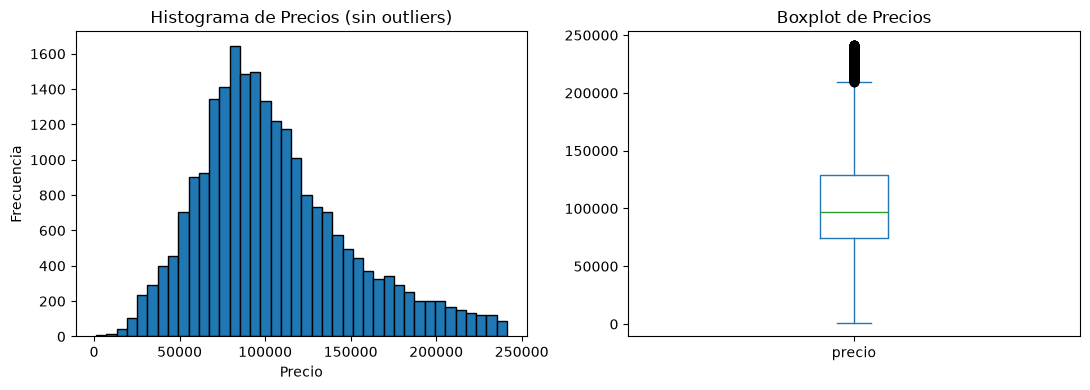

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
analisis_modelo["precio"].plot.hist(bins=40, ax=ax[0], edgecolor="black")
ax[0].set_title("Histograma de Precios (sin outliers)")
ax[0].set_xlabel("Precio")
ax[0].set_ylabel("Frecuencia")

analisis_modelo["precio"].plot.box(ax=ax[1])
ax[1].set_title("Boxplot de Precios")
plt.tight_layout()
plt.show()

### Modelo 1: regresión lineal múltiple

Ajustamos una primera regresión para explicar el precio a partir de la capacidad, las camas por huésped y los baños por huésped. En esta etapa todavía no controlamos por barrio ni por tipo de alojamiento.

In [ ]:
modelo1 = smf.ols("precio ~ accommodates + camas_por_huesped + banos_por_huesped",
                  data=analisis_modelo).fit()
print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:                 precio   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.198
Method:                 Least Squares   F-statistic:                     1882.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:06:36   Log-Likelihood:            -2.7514e+05
No. Observations:               22927   AIC:                         5.503e+05
Df Residuals:                   22923   BIC:                         5.503e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          6.923e+04   1327.96

### Modelo 2: controles por tipo de alojamiento y barrio

Agregamos como controles el tipo de alojamiento (si es departamento entero, habitación privada, etc.) y el barrio, para comparar alojamientos similares. Así podemos ver el efecto real de las camas y los baños sobre el precio sin que se mezclen propiedades muy distintas.

In [ ]:
analisis_modelo["barrio"] = dataset_limpio["neighbourhood_cleansed"]

modelo2 = smf.ols("precio ~ accommodates + camas_por_huesped + banos_por_huesped + C(room_type) + C(barrio)",
                  data=analisis_modelo).fit()

tabla = pd.DataFrame({"coef": modelo2.params, "p-valor": modelo2.pvalues})
print("R²:", round(modelo2.rsquared, 3))
tabla[~tabla.index.str.contains("barrio")].round(4)

R²: 0.31


,coef,p-valor
Intercept,40967.4826,0.0000
C(room_type)[T.Hotel room],60843.0421,0.0000
C(room_type)[T.Private room],-31750.7382,0.0000
C(room_type)[T.Shared room],-66645.9085,0.0000
accommodates,16376.7420,0.0000
camas_por_huesped,2019.1278,0.0431
banos_por_huesped,16671.9243,0.0000


### Multicolinealidad (VIF)

Calculamos el VIF de las variables numéricas del modelo para ver si alguna
está demasiado relacionada con las otras. Todos los valores quedaron por
debajo de 1,4, muy lejos del umbral de 5, por lo que no hay problemas de
multicolinealidad.

In [ ]:
X = add_constant(analisis_modelo[["accommodates", "camas_por_huesped", "banos_por_huesped"]])

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif[vif["variable"] != "const"].round(2)

,variable,VIF
1,accommodates,1.56
2,camas_por_huesped,1.07
3,banos_por_huesped,1.64


### Homocedasticidad

La regresión supone que los errores tienen una dispersión parecida para todos
los precios. Para revisarlo graficamos los residuos (la diferencia entre el
precio real y el predicho) contra los valores ajustados. Si se cumple el
supuesto, tendríamos que ver una nube pareja alrededor del cero.

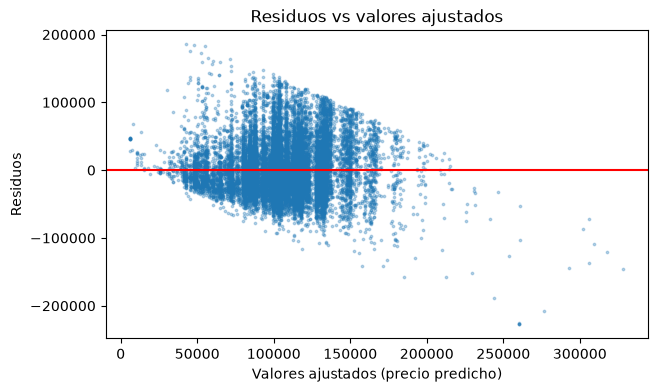

In [ ]:
residuos = modelo2.resid
ajustados = modelo2.fittedvalues

plt.figure(figsize=(7, 4))
plt.scatter(ajustados, residuos, s=3, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados (precio predicho)")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados")
plt.show()

La dispersión de los residuos es algo mayor en los extremos que en el centro,
por lo que el supuesto de varianza constante se cumple de forma aproximada
pero no perfecta. Lo tenemos en cuenta al interpretar los p-valores.

### Normalidad de los residuos

Para revisar si los errores del modelo se distribuyen de forma normal, miramos el gráfico Q-Q y calculamos el test de Jarque-Bera.

Test de Jarque-Bera: Estadístico = 3906.60, p-valor = 0.0000e+00
Asimetría (Skewness): 0.7460 | Curtosis: 4.3650


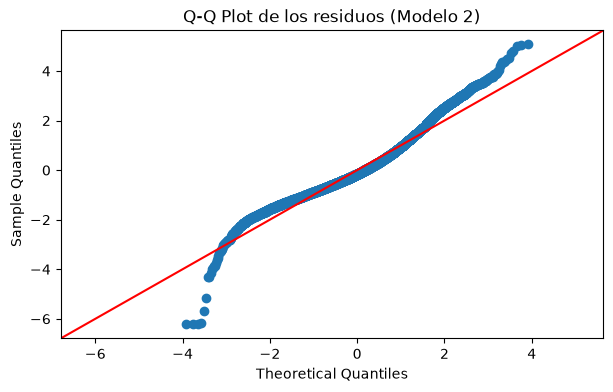

In [ ]:
# Evaluación de normalidad sin submuestreo: Jarque-Bera y Q-Q Plot completo
jb_stat, jb_pvalor, skew, kurt = sm.stats.stattools.jarque_bera(modelo2.resid)
print(f"Test de Jarque-Bera: Estadístico = {jb_stat:.2f}, p-valor = {jb_pvalor:.4e}")
print(f"Asimetría (Skewness): {skew:.4f} | Curtosis: {kurt:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
sm.qqplot(modelo2.resid, line="45", fit=True, ax=ax)
ax.set_title("Q-Q Plot de los residuos (Modelo 2)")
plt.show()

Vemos que en los extremos los residuos se apartan de la línea (hay alojamientos bastante más caros de lo que predice el modelo), por lo que la normalidad no es perfecta. De todas formas, al tener más de 20.000 observaciones, el tamaño de la muestra es lo bastante grande como para que las estimaciones y los p-valores sigan siendo confiables.

### Conclusión de la hipótesis C

La hipótesis planteaba que a igual capacidad, un alojamiento cobra más caro si da más independencia: una cama por persona, más baños por huésped y reserva automática. Con la regresión controlando por tipo de lugar y barrio encontramos:
- **Baños por huésped:** tiene un efecto positivo y significativo. Tener más baños por persona encarece el precio del alojamiento.
- **Camas por huésped:** una vez que controlamos por el tipo de propiedad, tener más camas por persona no muestra un aumento significativo en el precio.
- **Reserva automática:** no la pudimos evaluar porque la columna no tenía datos en la base.

En conclusión, la hipótesis se cumple solo para los baños.

//UNIVARIADAS 